<div style="background-color:#e3f0f5; padding:15px; border-radius:10px; border-left:6px solid #097a6d; color:#0c2e4c;">
<b>NB0 · Section 5 - Numerical Features (draft)</b><br>
</div>

<a id="sec-5"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5. Numerical Features</b>
</div>


In this section we go through the numerical features, one group at a time. For each one we check four things: how the values are distributed, if there are impossible values or placeholders, how many values are missing, and how the fatal rate changes with the feature. At the end of each part there is a decision (or a question) for NB1.

The numerical features are grouped like in the table of contents: temperature and dew point, altimeter, engine power, wind, visibility and ceiling, airport, aircraft and pilot. `wx_temp_c` is not analysed alone because it is only `wx_temp` converted to Celsius.

**Setup (only needed if this notebook runs alone)**

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns


learn = pd.read_csv("learn.csv", index_col=0)
print("learn:", learn.shape)

learn: (16979, 41)


First, a summary table of all numerical features (plus `ev_hour`), to see where the problems are.

In [2]:
num_cols = ["wx_temp", "wx_temp_c", "wx_dew_pt", "altimeter", "eng_power", "wind_dir_deg", "wind_vel_kts",
            "gust_kts", "vis_sm", "sky_ceil_ht", "apt_dist", "apt_elev", "acft_year", "total_seats",
            "num_eng", "pilot_age", "ev_hour"]

overview = pd.DataFrame({
    "missing (%)": learn[num_cols].isnull().mean() * 100,
    "zeros (%)": (learn[num_cols] == 0).mean() * 100,
    "min": learn[num_cols].min(),
    "median": learn[num_cols].median(),
    "max": learn[num_cols].max(),
    "skew": learn[num_cols].skew()
})
display(overview.round(2))

,missing (%),zeros (%),min,median,max,skew
wx_temp,0.00,5.04,-55.0,69.00,3005.00,43.36
wx_temp_c,0.00,0.37,-48.3,20.60,1651.70,43.34
wx_dew_pt,0.00,9.65,-39.0,46.00,3027.00,46.97
altimeter,0.00,8.89,0.0,30.01,3052.98,17.46
eng_power,10.61,1.01,0.0,189.00,264190.00,22.53
wind_dir_deg,0.00,25.84,0.0,146.00,360.00,0.16
wind_vel_kts,21.22,0.30,0.0,7.00,185.00,6.99
gust_kts,0.00,84.56,0.0,0.00,1077.00,52.07
vis_sm,4.25,0.23,0.0,10.00,5000.00,89.34
sky_ceil_ht,0.00,75.59,0.0,0.00,241340.00,11.64


From the table:

- `wx_temp`, `wx_dew_pt`, `altimeter`, `vis_sm`, `total_seats` and `wx_temp_c` have a huge skew because of a few impossible values (a few values like 3005 °F or 5000 miles are enough to ruin the shape).
- `gust_kts`, `sky_ceil_ht` and `apt_dist` are mostly 0 (85%, 76% and 77%). Here 0 is probably a real value ("no gust", "no ceiling", "at the airport"), but we check it below.
- `wind_dir_deg` is 0 in 26% of the rows, but directions go from 1 to 360, so many of these zeros are suspicious.
- `acft_year` (40%) and `apt_elev` (34%) are the ones with more missing values.
- `ev_hour` is a number but it is circular (23h is next to 0h), so it is analysed separately in 5.9.

<a id="sec-5-1"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.1. Temperature and Dew Point</b>
</div>


Temperature and dew point (both in °F) come from the nearest weather observation. In the USA the temperature is between about -60 and 130 °F, and the dew point can never be higher than the temperature. We count how many rows break these rules and plot the two variables together.

wx_temp == 0: 855
wx_dew_pt == 0: 1639
both == 0: 832
dew point == 0 and temperature > 40 F: 692
temperature > 130 F: 31
dew point > temperature: 268
max difference between wx_temp_c and the conversion of wx_temp: 0.0


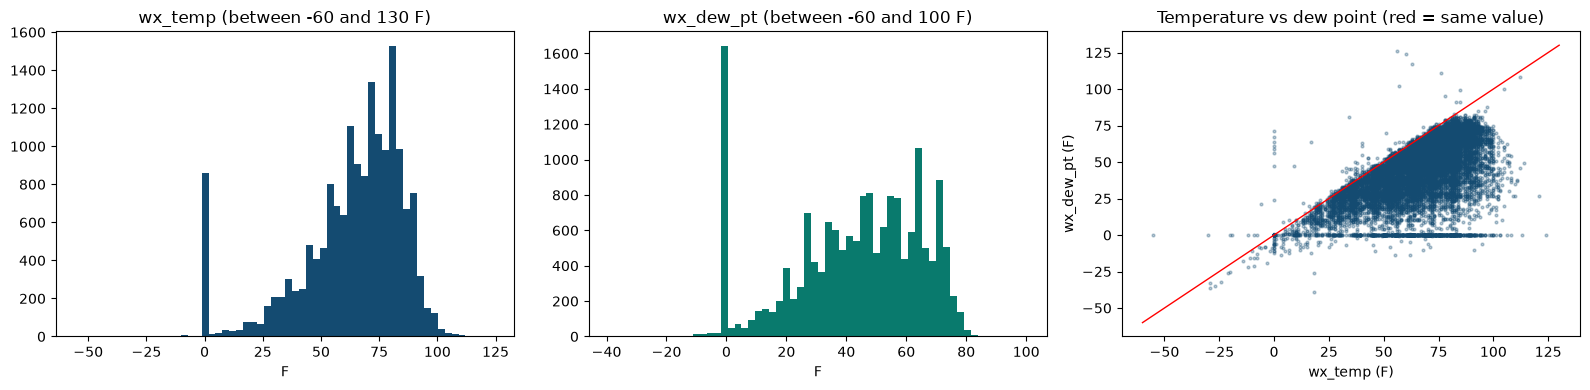


                        mean   size
both = 0               0.065    832
dew = 0 and temp > 40  0.042    692
normal                 0.182  15455


In [3]:
temp = learn["wx_temp"]
dew = learn["wx_dew_pt"]

print("wx_temp == 0:", (temp == 0).sum())
print("wx_dew_pt == 0:", (dew == 0).sum())
print("both == 0:", ((temp == 0) & (dew == 0)).sum())
print("dew point == 0 and temperature > 40 F:", ((dew == 0) & (temp > 40)).sum())
print("temperature > 130 F:", (temp > 130).sum())
print("dew point > temperature:", (dew > temp).sum())

# is wx_temp_c really just wx_temp converted?
diff = (((temp - 32) * 5 / 9).round(1) - learn["wx_temp_c"]).abs()
print("max difference between wx_temp_c and the conversion of wx_temp:", diff.max())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(temp[temp.between(-60, 130)], bins=60, color="#144b71")
axes[0].set_title("wx_temp (between -60 and 130 F)")
axes[0].set_xlabel("F")

axes[1].hist(dew[dew.between(-60, 100)], bins=60, color="#097a6d")
axes[1].set_title("wx_dew_pt (between -60 and 100 F)")
axes[1].set_xlabel("F")

ok = temp.between(-60, 130) & dew.between(-60, 130)
axes[2].scatter(temp[ok], dew[ok], s=4, alpha=0.3, color="#144b71")
axes[2].plot([-60, 130], [-60, 130], color="red", linewidth=1)
axes[2].set_title("Temperature vs dew point (red = same value)")
axes[2].set_xlabel("wx_temp (F)")
axes[2].set_ylabel("wx_dew_pt (F)")
plt.tight_layout()
plt.show()

temp_group = pd.Series("normal", index=learn.index)
temp_group[(dew == 0) & (temp > 40)] = "dew = 0 and temp > 40"
temp_group[(temp == 0) & (dew == 0)] = "both = 0"
print()
print(learn.groupby(temp_group)["fatal"].agg(["mean", "size"]).round(3))

**What we see**

- `wx_temp` has a big spike at exactly 0 (855 rows) and `wx_dew_pt` has an even bigger one (1,639 rows). In the scatter plot there is a dot cloud at (0, 0) and a horizontal line of points at dew point = 0 for all temperatures.
- 832 rows have both at 0. A real 0 °F in both at the same time, also in summer, is not believable, so it is "not measured" written as 0.
- There are 692 more rows with dew point = 0 and temperature above 40 °F. It is possible in a very dry desert, but not 692 times, so most of them are probably placeholders too.
- The fatal rate is only 6.5% when both are 0 and 4.2% when only the dew point is 0 (against 18.2% in the normal rows). So these zeros are not random: they say something about the accident (no weather data nearby).
- 31 rows have a temperature above 130 °F (values from 133 to 203 and 3005), which is impossible. 268 rows have a dew point higher than the temperature, which is also impossible.
- `wx_temp_c` is exactly `wx_temp` converted (maximum difference 0.0), so it is redundant.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- Drop `wx_temp_c` (it only repeats `wx_temp`, with the same errors).
- Put `wx_temp` and `wx_dew_pt` as missing when both are 0, when the dew point is 0 with temperature above 40 °F, and when the temperature is above 130 °F or the dew point is above the temperature.
- Keep this information as an indicator, together with the altimeter one (see 5.2), because the fatal rate is very different in these rows.
- Question: a temperature minus dew point "spread" may be more useful than the two values alone (small spread = fog or low clouds). We can test it after cleaning.
- Fill the remaining gaps with the median of the training set.

<a id="sec-5-2"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.2. Altimeter</b>
</div>


The altimeter setting is the air pressure in inches of mercury and the standard value is 29.92. In real life it stays between about 28 and 31. We split the values in groups to see what is wrong.

normal (25-35)                    15411
zero                               1510
around 3000 (no decimal point)       54
other impossible                      4
Name: count, dtype: int64

                                 mean   size
around 3000 (no decimal point)  0.074     54
normal (25-35)                  0.182  15411
other impossible                0.000      4
zero                            0.056   1510

other impossible values: [  16.    230.16   20.05 1974.02]
values around 3000 divided by 100:
count    54.00
mean     30.00
std       0.19
min      29.37
25%      29.92
50%      30.00
75%      30.13
max      30.53
Name: altimeter, dtype: float64

altimeter == 0 and wx_temp == 0: 771
altimeter == 0 and wind_vel_kts missing: 875
altimeter == 0 and wind_dir_deg == 0: 942


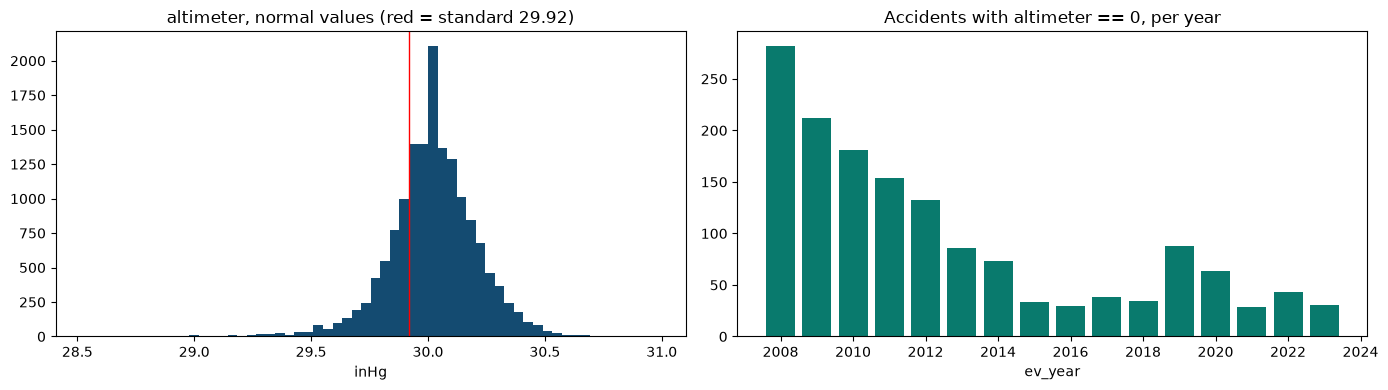

In [4]:
alt = learn["altimeter"]

alt_group = pd.Series("normal (25-35)", index=learn.index)
alt_group[alt == 0] = "zero"
alt_group[alt > 2800] = "around 3000 (no decimal point)"
alt_group[((alt > 0) & (alt < 25)) | ((alt > 35) & (alt <= 2800))] = "other impossible"

print(alt_group.value_counts())
print()
print(learn.groupby(alt_group)["fatal"].agg(["mean", "size"]).round(3))
print()
print("other impossible values:", alt[alt_group == "other impossible"].values)
print("values around 3000 divided by 100:")
print((alt[alt_group == "around 3000 (no decimal point)"] / 100).describe().round(2))

print()
print("altimeter == 0 and wx_temp == 0:", ((alt == 0) & (learn["wx_temp"] == 0)).sum())
print("altimeter == 0 and wind_vel_kts missing:", ((alt == 0) & learn["wind_vel_kts"].isnull()).sum())
print("altimeter == 0 and wind_dir_deg == 0:", ((alt == 0) & (learn["wind_dir_deg"] == 0)).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(alt[alt.between(28.5, 31)], bins=60, color="#144b71")
axes[0].axvline(29.92, color="red", linewidth=1)
axes[0].set_title("altimeter, normal values (red = standard 29.92)")
axes[0].set_xlabel("inHg")

zeros_by_year = (alt == 0).groupby(learn["ev_year"]).sum()
axes[1].bar(zeros_by_year.index, zeros_by_year.values, color="#097a6d")
axes[1].set_title("Accidents with altimeter == 0, per year")
axes[1].set_xlabel("ev_year")
plt.tight_layout()
plt.show()

**What we see**

- 15,411 rows (91%) are normal and sit in a narrow peak around 29.92 to 30.2.
- 1,510 rows have 0, which is "not measured".
- 54 rows are around 3000: they are normal pressures without the decimal point. Divided by 100 they go from 29.37 to 30.53 (mean 30.00), exactly the normal range, so they can be repaired.
- 4 other values cannot be repaired (16, 20.05, 230.16 and 1974.02).
- The rows with altimeter = 0 are the same rows where other weather values are also missing: 771 also have temperature = 0, 875 have no wind speed and 942 have wind direction = 0. So the altimeter 0 means that there was no weather observation for the accident.
- These rows have a fatal rate of only 5.6% (against 18.2% in the normal rows). They become less frequent over the years: 282 in 2008 and around 30 per year in the recent years (with a bump of 88 in 2019).
- With normal values, the altimeter has almost no relation with the target (Spearman correlation around 0), so the value of this feature is mostly in the "missing" information.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- Altimeter around 3000: divide by 100. Altimeter = 0 or any other impossible value: missing.
- Create one indicator `no_weather` (altimeter = 0), because it marks a group of accidents with a very different fatal rate and it is related to other weather columns (temperature, dew point, wind). In NB1 we should check if it is better to use one indicator for all weather columns, instead of one for each.
- Fill the rest with the median of the training set.

<a id="sec-5-3"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.3. Engine Power: Horsepower or Pounds of Thrust?</b>
</div>


According to the data dictionary, `eng_power` is in horsepower (HP) for piston and turboprop engines, but in pounds of thrust for jets. This means that the same column has two different units, so we compare it by engine type (`eng_type`).

eng_power missing: 1801 | eng_type missing: 602
eng_power missing by eng_type:
eng_type
REC     937
NaN     572
TP       96
TS       75
TF       70
NONE     23
UNK      11
TJ       10
ELEC      6
LR        1
Name: count, dtype: int64

eng_power by engine type:
            count     mean      std   min     25%     50%      75%       max
eng_type                                                                    
REC       13217.0    202.0    154.0   0.0   132.0   179.0    252.0    3293.0
TF          334.0  17441.0  24197.0   0.0  3261.0  8926.0  23993.0  264190.0
TJ           87.0   9312.0  12840.0   0.0  2072.0  3424.0  10717.0   63837.0
TP          765.0    846.0    566.0   0.0   661.0   754.0    908.0   10378.0
TS          733.0    722.0   2797.0  91.0   413.0   519.0    707.0   75552.0

eng_power == 0 by engine type:
eng_type
REC    147
TF      12
NaN      6
TP       4
TJ       2
Name: count, dtype: int64

Fatal rate by engine type:
           mean   size
eng_type              
ELEC

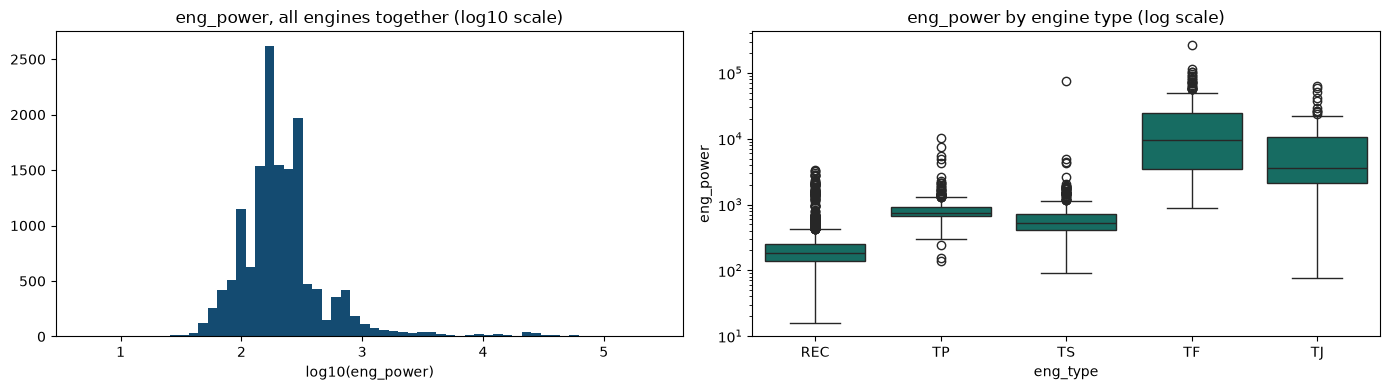

In [5]:
print("eng_power missing:", learn["eng_power"].isnull().sum(), "| eng_type missing:", learn["eng_type"].isnull().sum())
print("eng_power missing by eng_type:")
print(learn.loc[learn["eng_power"].isnull(), "eng_type"].value_counts(dropna=False))
print()

main_types = ["REC", "TP", "TS", "TF", "TJ"]
print("eng_power by engine type:")
print(learn[learn["eng_type"].isin(main_types)].groupby("eng_type")["eng_power"].describe().round(0))
print()
print("eng_power == 0 by engine type:")
print(learn.loc[learn["eng_power"] == 0, "eng_type"].value_counts(dropna=False))
print()
print("Fatal rate by engine type:")
print(learn.groupby("eng_type")["fatal"].agg(["mean", "size"]).round(3))

rec = learn[(learn["eng_type"] == "REC") & (learn["eng_power"] > 0)]
print()
print("Fatal rate by horsepower (piston engines only, 5 groups with the same size):")
print(rec.groupby(pd.qcut(rec["eng_power"], 5), observed=True)["fatal"].agg(["mean", "size"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(np.log10(learn.loc[learn["eng_power"] > 0, "eng_power"]), bins=60, color="#144b71")
axes[0].set_title("eng_power, all engines together (log10 scale)")
axes[0].set_xlabel("log10(eng_power)")

sns.boxplot(data=learn[(learn["eng_type"].isin(main_types)) & (learn["eng_power"] > 0)],
            x="eng_type", y="eng_power", order=main_types, color="#097a6d", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("eng_power by engine type (log scale)")
plt.tight_layout()
plt.show()

**What we see**

- `eng_power` has 1,801 missing values (10.6%). 937 of them are piston engines and 572 have no `eng_type` either.
- The scale changes a lot with the engine type: the median is 179 HP for piston (REC), 754 for turboprop (TP), 519 for turboshaft (TS), but 3,424 lbs for turbojets (TJ) and 8,926 lbs for turbofans (TF). In the histogram, all the engines together make one peak around 200 and a long tail to the right, which is the jets.
- 171 rows have `eng_power` = 0 (147 piston, 12 turbofan, 4 turboprop, 2 turbojet and 6 with no engine type). An engine with zero power is not possible.
- There are a few extreme values left (a turboshaft with 75,552 and a piston engine with 3,293), to check in NB1.
- The fatal rate changes with the engine type: turboprop 22.9%, turboshaft 19.2%, piston 16.9% and turbofan only 9.2%. Inside the piston engines, accidents with more than 276 HP are the most fatal (22.0%), against 13.5% to 13.8% in the middle groups. This is probably the effect of the type of aircraft (faster and bigger planes), not of the power itself.
- Other engine types (ELEC, NONE, UNK and so on) have very few rows.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- Do not use `eng_power` as it is. Split it in two features: `hp` (for engines measured in horsepower) and `thrust_lbs` (for TF and TJ), so each column has only one unit. The other option is a rank of the power inside each `eng_type`.
- `eng_power` = 0 becomes missing, then median inside the engine type (training set only) and a missing indicator.
- Question: 30 rows have a power but no `eng_type`. We need to decide in which of the two features they go (maybe by looking at the aircraft category).
- Use a log scale (or a cap) for the power, because of the extreme values, at least for the models that are sensitive to them.

<a id="sec-5-4"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.4. Wind and Gusts</b>
</div>


Here we look at wind direction (degrees, 1 to 360), wind speed and gust speed (knots), and at `gust_ind`, the gust indicator that should agree with `gust_kts`.

wind_dir_deg == 0: 4387
  ... and wind_vel_kts missing: 3543
  ... and wind_vel_kts == 0 (calm wind): 51
  ... and wind_vel_kts > 0: 793
wind_dir_deg > 360: 0

wind_vel_kts missing: 3603 | > 50 kts: 8 -> [115.  79.  76.  98. 185. 100.  65.  75.]
gust_kts > 0: 2621 | > 60 kts: 1 -> [1077]
gust below wind speed (gust > 0): 24

gust_ind vs gust_kts > 0 (all rows):
gust_kts  False  True 
gust_ind              
F          3429   2616
T         10929      5

gust_ind vs gust_kts > 0 (only rows with a real weather observation):
gust_kts  False  True 
gust_ind              
F          2712   2385
T         10309      5

Fatal rate with / without gusts:
           mean   size
gust_kts              
False     0.171  14358
True      0.163   2621
Median wind speed by target:
fatal
0    7.0
1    7.0
Name: wind_vel_kts, dtype: float64


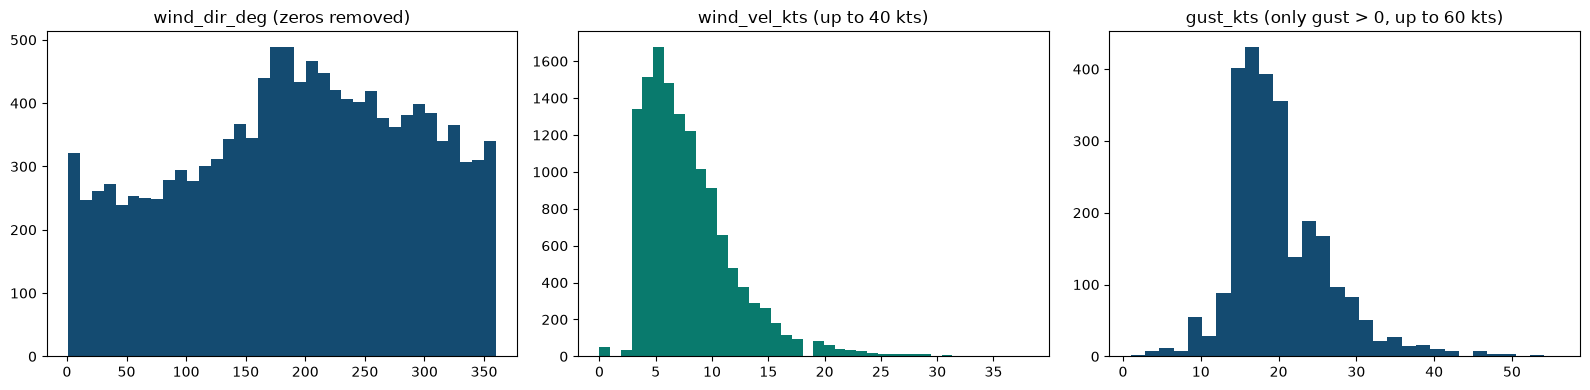

In [6]:
wdir = learn["wind_dir_deg"]
wvel = learn["wind_vel_kts"]
gust = learn["gust_kts"]

print("wind_dir_deg == 0:", (wdir == 0).sum())
print("  ... and wind_vel_kts missing:", ((wdir == 0) & wvel.isnull()).sum())
print("  ... and wind_vel_kts == 0 (calm wind):", ((wdir == 0) & (wvel == 0)).sum())
print("  ... and wind_vel_kts > 0:", ((wdir == 0) & (wvel > 0)).sum())
print("wind_dir_deg > 360:", (wdir > 360).sum())
print()
print("wind_vel_kts missing:", wvel.isnull().sum(), "| > 50 kts:", (wvel > 50).sum(), "->", wvel[wvel > 50].values)
print("gust_kts > 0:", (gust > 0).sum(), "| > 60 kts:", (gust > 60).sum(), "->", gust[gust > 60].values)
print("gust below wind speed (gust > 0):", ((gust > 0) & (gust < wvel)).sum())
print()
print("gust_ind vs gust_kts > 0 (all rows):")
print(pd.crosstab(learn["gust_ind"].fillna("missing"), gust > 0))
print()
valid_wx = learn["altimeter"].between(25, 35)
print("gust_ind vs gust_kts > 0 (only rows with a real weather observation):")
print(pd.crosstab(learn.loc[valid_wx, "gust_ind"].fillna("missing"), gust[valid_wx] > 0))
print()
print("Fatal rate with / without gusts:")
print(learn.groupby(gust > 0)["fatal"].agg(["mean", "size"]).round(3))
print("Median wind speed by target:")
print(learn.groupby("fatal")["wind_vel_kts"].median())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(wdir[wdir > 0], bins=36, color="#144b71")
axes[0].set_title("wind_dir_deg (zeros removed)")
axes[1].hist(wvel[wvel <= 40], bins=40, color="#097a6d")
axes[1].set_title("wind_vel_kts (up to 40 kts)")
axes[2].hist(gust[(gust > 0) & (gust <= 60)], bins=30, color="#144b71")
axes[2].set_title("gust_kts (only gust > 0, up to 60 kts)")
plt.tight_layout()
plt.show()

**What we see**

- `wind_dir_deg` is 0 in 4,387 rows, but directions go from 1 to 360. In 3,543 of them the wind speed is also missing, so the 0 is a placeholder. Only 51 have a calm wind (speed 0), where the direction is not important. The 793 rows with 0 and speed above 0 may be variable winds, but we cannot confirm that. There are no values above 360.
- `wind_vel_kts` is missing in 3,603 rows (21%). 8 values are above 50 knots (up to 185 knots); they are very strong winds and they may be real (hurricane), so we do not call them errors, but 185 is suspicious.
- `gust_kts` is 0 in most rows (no gust) and has one impossible value (1,077 knots). In 24 rows the gust is lower than the wind speed, which should not happen.
- `gust_ind` does not agree with the dictionary: the value T (gusts?) appears in 10,934 rows, but only 5 of them have a gust above 0. The value F has gusts in 2,616 rows and no gust in 3,429. Even if we only keep the rows with a real weather observation (altimeter between 25 and 35), the problem is the same. So T behaves like "no gust" and F is a mix, which makes the column hard to trust.
- Wind speed and gusts have almost no relation with the target: the median wind speed is 7 knots for fatal and not fatal accidents, and the fatal rate is 16.3% with gusts and 17.1% without.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- `wind_dir_deg` = 0 with missing wind speed becomes missing (it is the "no weather" group of 5.2). For the 0 with speed above 0 we keep the question open. Wind direction is circular (359 is close to 1), so if we use it, it should be transformed with sine and cosine or turned into groups. Maybe a headwind/crosswind feature is not possible, because we do not have the runway direction.
- `wind_vel_kts` above 100 and `gust_kts` = 1,077 become missing; gust lower than the wind speed is a small number of rows (24) to be set as missing or equal to the wind speed.
- Create `has_gust` = `gust_kts` > 0 from the number, and not from `gust_ind`. We check `gust_ind` in the categorical features, but we do not trust it as it is.
- Missing wind speed gets an indicator and the median of the training set.

<a id="sec-5-5"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.5. Visibility and Cloud Ceiling</b>
</div>


Visibility is in statute miles and the cloud ceiling height is in feet. The ceiling is 0 when there is no ceiling, so we compare `sky_ceil_ht` with `sky_cond_ceil`. These two are the ones that are related to bad weather, so we also look at the fatal rate for groups of values.

vis_sm missing: 721
vis_sm == 10: 14147 | > 10: 445 | == 0: 39
most common values above 10:
vis_sm
20.0     115
15.0      65
30.0      64
50.0      50
40.0      43
25.0      34
12.0      22
100.0     12
Name: count, dtype: int64
values above 100: [5000. 4500.]

Fatal rate by visibility:
         mean   size
vis_sm              
<= 1    0.512    172
1-3     0.429    259
3-5     0.378    283
5-10    0.238    952
= 10    0.159  14147
> 10    0.090    445

sky_ceil_ht == 0: 12834 | > 0: 4145
sky_ceil_ht > 40000: [241340  40331]

sky_cond_ceil vs having a ceiling height > 0:
sky_ceil_ht    False  True 
sky_cond_ceil              
BKN               66   2508
NONE           10641     21
OVC               30   1567
UNK               92      3
VV                18     31
missing         1987     15

Fatal rate by ceiling height (ft):
                 mean   size
sky_ceil_ht                 
no ceiling (0)  0.145  12834
1-500           0.568    278
500-1000        0.521    259
1000-3000       0.

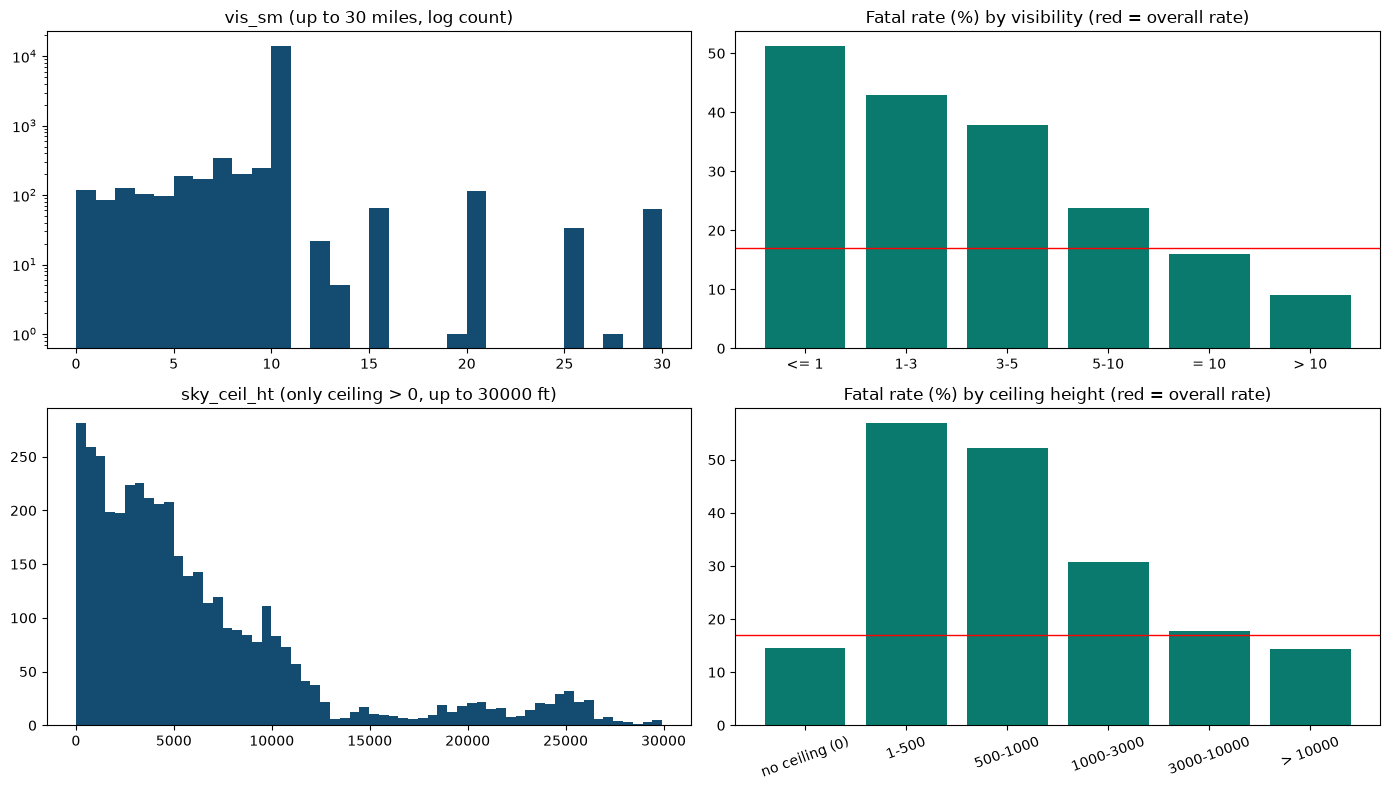

In [7]:
vis = learn["vis_sm"]
ceil = learn["sky_ceil_ht"]

print("vis_sm missing:", vis.isnull().sum())
print("vis_sm == 10:", (vis == 10).sum(), "| > 10:", (vis > 10).sum(), "| == 0:", (vis == 0).sum())
print("most common values above 10:")
print(vis[vis > 10].value_counts().head(8))
print("values above 100:", vis[vis > 100].values)
print()

vis_bins = pd.cut(vis, [-1, 1, 3, 5, 9.99, 10, 100000], labels=["<= 1", "1-3", "3-5", "5-10", "= 10", "> 10"])
vis_rate = learn.groupby(vis_bins, observed=True)["fatal"].agg(["mean", "size"])
print("Fatal rate by visibility:")
print(vis_rate.round(3))
print()

print("sky_ceil_ht == 0:", (ceil == 0).sum(), "| > 0:", (ceil > 0).sum())
print("sky_ceil_ht > 40000:", ceil[ceil > 40000].values)
print()
print("sky_cond_ceil vs having a ceiling height > 0:")
print(pd.crosstab(learn["sky_cond_ceil"].fillna("missing"), ceil > 0))
print()

ceil_bins = pd.cut(ceil, [-1, 0, 500, 1000, 3000, 10000, 1000000], labels=["no ceiling (0)", "1-500", "500-1000", "1000-3000", "3000-10000", "> 10000"])
ceil_rate = learn.groupby(ceil_bins, observed=True)["fatal"].agg(["mean", "size"])
print("Fatal rate by ceiling height (ft):")
print(ceil_rate.round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].hist(vis[vis <= 30], bins=30, color="#144b71")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("vis_sm (up to 30 miles, log count)")
axes[0, 1].bar(vis_rate.index.astype(str), vis_rate["mean"] * 100, color="#097a6d")
axes[0, 1].axhline(learn["fatal"].mean() * 100, color="red", linewidth=1)
axes[0, 1].set_title("Fatal rate (%) by visibility (red = overall rate)")
axes[1, 0].hist(ceil[(ceil > 0) & (ceil <= 30000)], bins=60, color="#144b71")
axes[1, 0].set_title("sky_ceil_ht (only ceiling > 0, up to 30000 ft)")
axes[1, 1].bar(ceil_rate.index.astype(str), ceil_rate["mean"] * 100, color="#097a6d")
axes[1, 1].axhline(learn["fatal"].mean() * 100, color="red", linewidth=1)
axes[1, 1].set_title("Fatal rate (%) by ceiling height (red = overall rate)")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**What we see**

*Visibility*

- 14,147 rows (83%) have visibility 10, which is the normal maximum. 721 values are missing.
- 445 rows are above 10 (20, 15, 30, 50 miles and so on) and two are clearly impossible (4,500 and 5,000). The others could be real in stations that report more than 10 miles.
- The fatal rate goes down as the visibility improves: 51.2% with up to 1 mile, 42.9% between 1 and 3, 37.8% between 3 and 5, 23.8% between 5 and 10, 15.9% with exactly 10 and only 9.0% when above 10. This is one of the clearest relations with the target.

*Cloud ceiling*

- 12,834 rows (76%) have height 0 and 4,145 have a ceiling. `sky_cond_ceil` agrees with this in most cases (NONE with 0 and BKN/OVC with a height), but there are some inconsistencies: 114 rows have BKN, OVC or VV with height 0, 21 have NONE with a height, and 15 have no `sky_cond_ceil` but have a height.
- Two heights are not believable for a cloud ceiling: 241,340 and 40,331 feet.
- Low ceilings are dangerous: 56.8% of the accidents with a ceiling up to 500 feet are fatal and 52.1% between 500 and 1000, against 14.5% with no ceiling and 14.4% above 10,000 feet. The rate goes down step by step with the height.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- `vis_sm` = 4,500 and 5,000 become missing. The other values above 10 stay (they have a different fatal rate, 9.0%). We can cap the visibility at 10 and add an indicator "above 10", or keep it as it is for the tree models. For the models that need it, apply a log scale.
- `sky_ceil_ht` above 40,000 becomes missing. We keep 0 (it is real: no ceiling) but create `has_ceiling` as an indicator and a ceiling height where "no ceiling" is not mixed with "very low ceiling". For the linear models, a log scale for the height.
- Question: for BKN/OVC/VV with height 0 (114 rows), we need to decide if the height is missing (probably yes).
- Both features are strong, so we keep them in the model. Missing visibility gets the median of the training set and an indicator (in the missing-values section, the fatal rate with missing visibility was around 9%).

<a id="sec-5-6"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.6. Distance to the Airport and Airport Elevation</b>
</div>


`apt_dist` is the distance to the nearest airport in miles and `apt_elev` is the elevation of that airport in feet. Almost 77% of the accidents have `apt_dist` = 0, so we need to understand what that 0 means and what the huge values are.

apt_dist == 0: 13119 (77%)
apt_dist between 1 and 25 miles: 3691
apt_dist between 26 and 100 miles: 99
apt_dist between 101 and 500: 18
apt_dist > 500: 52

values above 500 if they were feet, in miles: 0.12 to 1.37

Fatal rate by distance to the airport (miles):
           mean   size
apt_dist              
0         0.141  13119
1         0.225   2381
2-5       0.328    856
6-10      0.401    247
11-25     0.357    207
26-100    0.364     99
101-500   0.222     18
> 500     0.096     52

apt_elev missing: 5712
  ... and apt_dist == 0: 5586
  ... and apt_dist > 0: 126
apt_elev == 33333: 1
apt_elev above 9000 ft: [9919. 9055. 9955. 9141. 9769. 9028. 9035. 9823. 9272.]
apt_elev below -200 ft: [-214. -221. -224.]

Fatal rate by airport elevation (ft):
            mean  size
apt_elev              
<= 0       0.105    76
0-500      0.148  4549
500-1500   0.151  3889
1500-3000  0.151   994
3000-6000  0.128  1390
> 6000     0.141   368


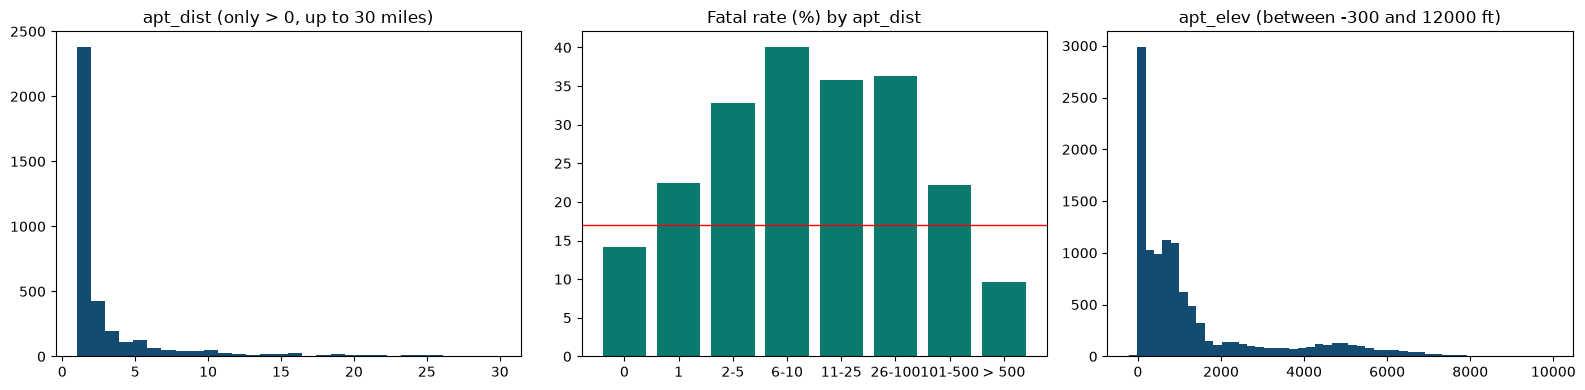

In [8]:
dist = learn["apt_dist"]
elev = learn["apt_elev"]

print("apt_dist == 0:", (dist == 0).sum(), f"({(dist == 0).mean():.0%})")
print("apt_dist between 1 and 25 miles:", dist.between(1, 25).sum())
print("apt_dist between 26 and 100 miles:", dist.between(26, 100).sum())
print("apt_dist between 101 and 500:", dist.between(101, 500).sum())
print("apt_dist > 500:", (dist > 500).sum())
print()

far = dist[dist > 500]
print("values above 500 if they were feet, in miles:", (far / 5280).round(2).min(), "to", (far / 5280).round(2).max())
print()

dist_bins = pd.cut(dist, [-1, 0, 1, 5, 10, 25, 100, 500, 100000],
                   labels=["0", "1", "2-5", "6-10", "11-25", "26-100", "101-500", "> 500"])
dist_rate = learn.groupby(dist_bins, observed=True)["fatal"].agg(["mean", "size"])
print("Fatal rate by distance to the airport (miles):")
print(dist_rate.round(3))
print()

print("apt_elev missing:", elev.isnull().sum())
print("  ... and apt_dist == 0:", (elev.isnull() & (dist == 0)).sum())
print("  ... and apt_dist > 0:", (elev.isnull() & (dist > 0)).sum())
print("apt_elev == 33333:", (elev == 33333).sum())
print("apt_elev above 9000 ft:", elev[(elev > 9000) & (elev != 33333)].values)
print("apt_elev below -200 ft:", elev[elev < -200].values)
print()
elev_bins = pd.cut(elev, [-300, 0, 500, 1500, 3000, 6000, 12000], labels=["<= 0", "0-500", "500-1500", "1500-3000", "3000-6000", "> 6000"])
print("Fatal rate by airport elevation (ft):")
print(learn.groupby(elev_bins, observed=True)["fatal"].agg(["mean", "size"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(dist[(dist > 0) & (dist <= 30)], bins=30, color="#144b71")
axes[0].set_title("apt_dist (only > 0, up to 30 miles)")
axes[1].bar(dist_rate.index.astype(str), dist_rate["mean"] * 100, color="#097a6d")
axes[1].axhline(learn["fatal"].mean() * 100, color="red", linewidth=1)
axes[1].set_title("Fatal rate (%) by apt_dist")
axes[2].hist(elev[elev.between(-300, 12000)], bins=50, color="#144b71")
axes[2].set_title("apt_elev (between -300 and 12000 ft)")
plt.tight_layout()
plt.show()

**What we see**

*Distance*

- 13,119 rows (77%) have distance 0 (probably the accident happened at the airport itself), 3,691 are between 1 and 25 miles and 99 between 26 and 100. This one is a real zero, not a missing value.
- 52 rows have a distance above 500, up to 7,208 miles, which is impossible in the USA. If the values were in feet, they would be between 0.12 and 1.37 miles. This is supported by the fatal rate: 9.6% in these rows, similar to the accidents at the airport (14.1%) and not to the accidents far away (about 36%). So they are probably in feet. The 18 rows between 101 and 500 are unclear (fatal rate 22.2%).
- The farther the accident is from an airport, the more dangerous it is: 14.1% at 0 miles, 22.5% at 1 mile, 32.8% from 2 to 5 miles and 36% to 40% from 6 to 100 miles. This is one of the best features of the section.

*Elevation*

- `apt_elev` has 5,712 missing values (34%), and 5,586 of them are in rows with `apt_dist` = 0. So it is not missing at random, it is linked to the accident being at the airport.
- One row has 33,333, which is a placeholder. The values above 9,000 feet (9,028 to 9,955) look like real high airports (the highest public airport in the USA is at about 9,900 feet), and the three negative values (-214 to -224) are close to the lowest airports (Death Valley area, around -210 feet). So they are kept.
- The fatal rate is almost flat with the elevation (between 10% and 15%), so this feature has little relation with the target.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- `apt_dist` above 500: divide by 5,280 (feet to miles), as a hypothesis supported by the fatal rate. The 18 rows between 101 and 500 stay as they are.
- Keep the zeros and create `at_airport` (`apt_dist` = 0). Because of the long tail, a log of the distance (`log1p`) or groups (0, 1, 2-5, 6-25, more than 25) should be tested.
- `apt_elev` = 33,333 becomes missing. The other values stay. Median of the training set and an indicator, since the missing is linked to `apt_dist` = 0 and also with a different fatal rate (21% to 22%, in the missing values section).

<a id="sec-5-7"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.7. Aircraft Year, Seats and Number of Engines</b>
</div>


These three describe the aircraft: the year it was built, how many seats it has and how many engines. We look for impossible values and also for values that look strange but are real (a plane with 150 seats is not an error, it is an airliner).

--- acft_year ---
missing: 6816 (40%)
== 0: 1 | between 1 and 1902: 2 -> [1062.  163.]
built after the accident year: 86
how many years after:
1.0    75
2.0    10
3.0     1
Name: count, dtype: int64

missing acft_year by aircraft category:
acft_category
AIR     0.40
BALL    0.43
BLIM    1.00
GLI     0.46
GYRO    0.31
HELI    0.38
PLFT    0.50
PPAR    0.67
RCKT    0.00
ULTR    0.76
WSFT    0.52
Name: acft_year, dtype: float64

Fatal rate by aircraft age at the accident (years):
        mean  size
<= 0   0.189   222
1-5    0.172   866
6-10   0.199   790
11-20  0.193  1587
21-40  0.190  2202
41-60  0.178  3214
> 60   0.116  1279

--- total_seats ---
missing: 1206 | == 0: 37 | > 600: 4 -> [8300. 3300. 2500. 1979.]
total_seats
2.0    5663
4.0    5489
6.0    1418
1.0    1295
5.0     431
3.0     390
7.0     280
8.0     192
Name: count, dtype: int64
Fatal rate by number of seats:
              mean  size
total_seats             
0            0.027    37
1            0.176  1295
2            0.

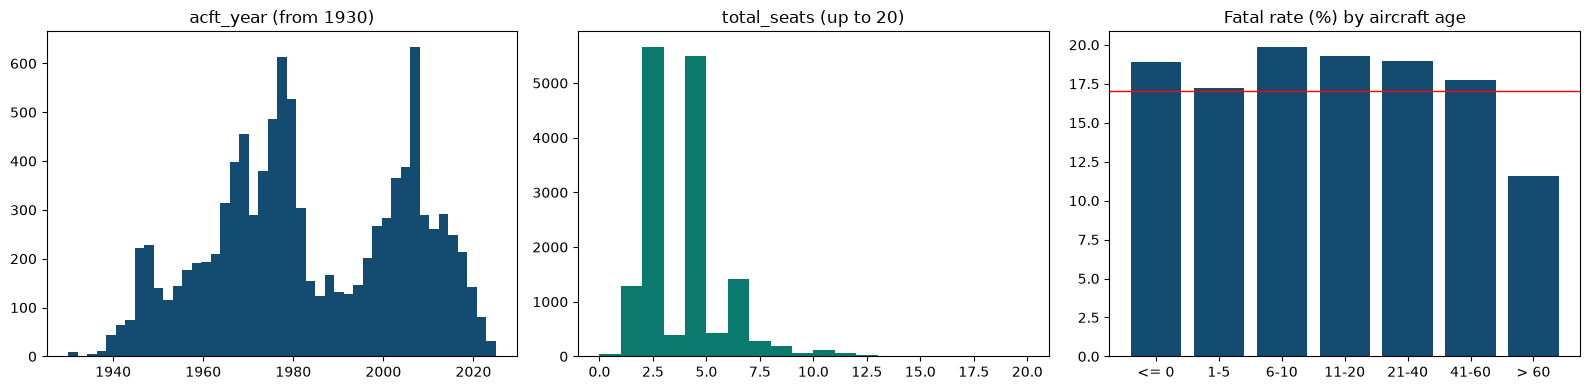

In [9]:
year = learn["acft_year"]
seats = learn["total_seats"]
neng = learn["num_eng"]
cat = learn["acft_category"].str.upper()     # only to compare, learn is not changed

print("--- acft_year ---")
print("missing:", year.isnull().sum(), f"({year.isnull().mean():.0%})")
print("== 0:", (year == 0).sum(), "| between 1 and 1902:", ((year > 0) & (year < 1903)).sum(), "->", year[(year > 0) & (year < 1903)].values)
gap = (year - learn["ev_year"])[year > learn["ev_year"]]
print("built after the accident year:", len(gap))
print("how many years after:")
print(gap.value_counts().sort_index())
print()
print("missing acft_year by aircraft category:")
print(learn.groupby(cat)["acft_year"].apply(lambda s: s.isnull().mean()).round(2))
print()

age = (learn["ev_year"] - year)[(year > 1902) & (year <= learn["ev_year"])]
age_bins = pd.cut(learn["ev_year"] - year, [-10, 0, 5, 10, 20, 40, 60, 200], labels=["<= 0", "1-5", "6-10", "11-20", "21-40", "41-60", "> 60"])
age_rate = learn.groupby(age_bins, observed=True)["fatal"].agg(["mean", "size"])
print("Fatal rate by aircraft age at the accident (years):")
print(age_rate.round(3))
print()

print("--- total_seats ---")
print("missing:", seats.isnull().sum(), "| == 0:", (seats == 0).sum(), "| > 600:", (seats > 600).sum(), "->", seats[seats > 600].values)
print(seats.value_counts().head(8))
seat_bins = pd.cut(seats, [-1, 0, 1, 2, 4, 6, 10, 50, 100000], labels=["0", "1", "2", "3-4", "5-6", "7-10", "11-50", "> 50"])
print("Fatal rate by number of seats:")
print(learn.groupby(seat_bins, observed=True)["fatal"].agg(["mean", "size"]).round(3))
print()

print("--- num_eng ---")
print(neng.value_counts(dropna=False).sort_index())
print("Fatal rate by number of engines:")
print(learn.groupby("num_eng")["fatal"].agg(["mean", "size"]).round(3))
print("num_eng == 0 by aircraft category:")
print(cat[neng == 0].value_counts())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(year[year >= 1930], bins=45, color="#144b71")
axes[0].set_title("acft_year (from 1930)")
axes[1].hist(seats[seats <= 20], bins=20, color="#097a6d")
axes[1].set_title("total_seats (up to 20)")
axes[2].bar(age_rate.index.astype(str), age_rate["mean"] * 100, color="#144b71")
axes[2].axhline(learn["fatal"].mean() * 100, color="red", linewidth=1)
axes[2].set_title("Fatal rate (%) by aircraft age")
plt.tight_layout()
plt.show()

**What we see**

*Aircraft year*

- 6,816 rows (40%) are missing. The percentage is similar in the main aircraft categories (31% to 52%) and higher only in powered parachutes and ultralights (67% and 76%, with very few rows), so the missing does not come from one type of aircraft.
- There is one 0 and two values before 1903 (1,062 and 163), which are not possible (the first airplane flew in 1903).
- 86 aircraft were "built" after the accident year, but 75 of them by only one year and 10 by two. This is normal, because the year of the model is often one year ahead of the real date. So these rows are not errors; only the very big differences would be (there is one with 3 years).
- The fatal rate is similar for aircraft up to 60 years old (17% to 20%) and drops to 11.6% for those older than 60 years.

*Seats*

- Most aircraft have 2 or 4 seats. 1,206 values are missing (7.1%), 37 have 0 seats and 4 have more than 600 (8,300, 3,300, 2,500 and 1,979), which are impossible.
- Aircraft with more than 50 seats (217 rows) are real airliners, and only 0.9% of their accidents are fatal. The planes with 5 or 6 seats have the highest fatal rate (23.6%). The rows with 0 seats have a fatal rate of 2.7%.

*Number of engines*

- Most have 1 engine (14,574) or 2 (1,646). 485 values are missing. 243 have 0 engines: 241 are gliders and balloons (real), but 2 are airplanes (errors).
- The fatal rate is 16.5% with one engine and 22.2% with two. Aircraft with 3 or more engines are only 31 rows.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- `acft_year` = 0 and the values before 1903 become missing. Years after the accident are only errors if the difference is more than 2 years (1 row). Instead of the year, a feature "aircraft age" (`ev_year` - `acft_year`, with a minimum of 0) is more useful and easy to explain. The missing (40%) gets an indicator and the median.
- `total_seats` = 0 and above 600 become missing. The values between 50 and 600 stay, they are real airliners. Because of the skew, a log or groups of seats can be tested.
- `num_eng` = 0 is only valid for gliders and balloons; the 2 airplanes with 0 engines become missing. Median or mode by category for the missing.
- Missing values in these three get an indicator.

<a id="sec-5-7-1"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.7.1. The Required Feature: seat_vintage_ratio</b>
</div>


The project brief asks for a feature called `seat_vintage_ratio` = `total_seats` / `acft_year`, which must stay in the final model. Before NB1 we check what happens when it is calculated with this data (on a copy, nothing is changed).

In [10]:
# only a copy, learn is not changed
ratio = learn["total_seats"] / learn["acft_year"]

print("seat_vintage_ratio = total_seats / acft_year")
print("missing:", ratio.isnull().sum(), f"({ratio.isnull().mean():.0%})")
print("infinite (acft_year == 0):", np.isinf(ratio).sum())
print(ratio[~np.isinf(ratio)].describe().round(5))
print()

valid = ~np.isinf(ratio) & ratio.notnull()
print("Spearman correlation with fatal:")
print("  seat_vintage_ratio:", round(ratio[valid].corr(learn.loc[valid, "fatal"], method="spearman"), 3))
print("  total_seats       :", round(learn.loc[valid, "total_seats"].corr(learn.loc[valid, "fatal"], method="spearman"), 3))
print("  acft_year         :", round(learn.loc[valid, "acft_year"].corr(learn.loc[valid, "fatal"], method="spearman"), 3))
print("Spearman correlation between seat_vintage_ratio and total_seats:",
      round(ratio[valid].corr(learn.loc[valid, "total_seats"], method="spearman"), 3))

seat_vintage_ratio = total_seats / acft_year
missing: 7586 (45%)
infinite (acft_year == 0): 1
count    9392.00000
mean        0.00306
std         0.01493
min         0.00000
25%         0.00100
50%         0.00199
75%         0.00204
max         1.00000
dtype: float64

Spearman correlation with fatal:
  seat_vintage_ratio: 0.013
  total_seats       : 0.026
  acft_year         : 0.037
Spearman correlation between seat_vintage_ratio and total_seats: 0.952


**What we see**

- The ratio is missing in 7,586 rows (45%), because `total_seats` or `acft_year` is missing, and it is infinite in one row (`acft_year` = 0). Both cases need to be solved before creating it in NB1, since the impossible values and the missing values of the two columns pass directly to the ratio.
- Since `acft_year` is always around 1,940 to 2,020, dividing by it just divides the seats by about 2,000: the ratio is almost the number of seats on another scale. Its Spearman correlation with `total_seats` is 0.95.
- The relation with the target is weak (Spearman 0.013, against 0.026 for `total_seats` and 0.037 for `acft_year`).

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- Create `seat_vintage_ratio` only after cleaning `total_seats` and `acft_year` (impossible values as missing, and then the imputation), and make sure that no infinite value is created.
- Keep it in the final model as the brief says, and in the feature engineering section explain what we saw: it is highly correlated with `total_seats`, so it adds little information. This is a result we can show with numbers.

<a id="sec-5-8"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.8. Pilot Age</b>
</div>


`pilot_age` is the age of the pilot in command. We look for impossible ages and see how the fatal rate changes with the age.

missing: 122 | fatal rate when missing: 0.115
pilot_age == 0: 4 | between 1 and 13: 2 | > 100: 6
ages below 14 or above 100: [0, 0, 0, 0, 1, 7, 115, 116, 144, 181, 199, 214]
ages 14 and 15: 11
pilots below 16 in airplanes: [0, 0, 0, 0, 1, 7, 14, 15, 15, 15, 15, 15, 15, 15]

Fatal rate by pilot age:
            mean  size
pilot_age             
< 14       0.000     6
14-20      0.106   255
21-30      0.118  1697
31-40      0.155  1960
41-50      0.167  2831
51-60      0.172  3997
61-70      0.192  3888
71-80      0.194  1836
81-100     0.202   381
> 100      0.000     6


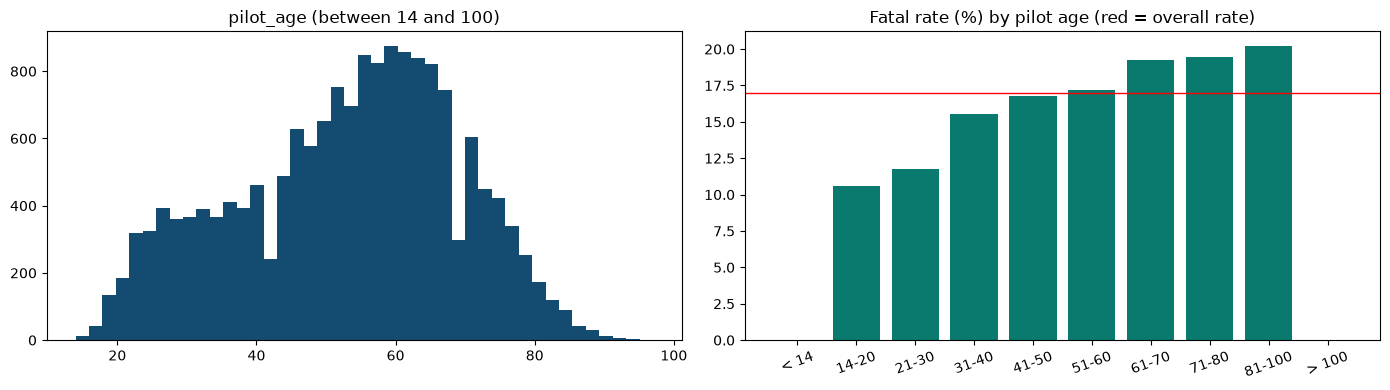

In [11]:
page = learn["pilot_age"]

print("missing:", page.isnull().sum(), "| fatal rate when missing:", round(learn.loc[page.isnull(), "fatal"].mean(), 3))
print("pilot_age == 0:", (page == 0).sum(), "| between 1 and 13:", ((page > 0) & (page < 14)).sum(), "| > 100:", (page > 100).sum())
print("ages below 14 or above 100:", sorted(page[(page < 14) | (page > 100)].astype(int).tolist()))
print("ages 14 and 15:", ((page >= 14) & (page < 16)).sum())
print("pilots below 16 in airplanes:", sorted(page[(cat == "AIR") & (page < 16)].astype(int).tolist()))
print()

page_bins = pd.cut(page, [-1, 13, 20, 30, 40, 50, 60, 70, 80, 100, 300],
                   labels=["< 14", "14-20", "21-30", "31-40", "41-50", "51-60", "61-70", "71-80", "81-100", "> 100"])
page_rate = learn.groupby(page_bins, observed=True)["fatal"].agg(["mean", "size"])
print("Fatal rate by pilot age:")
print(page_rate.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(page[page.between(14, 100)], bins=43, color="#144b71")
axes[0].set_title("pilot_age (between 14 and 100)")
axes[1].bar(page_rate.index.astype(str), page_rate["mean"] * 100, color="#097a6d")
axes[1].axhline(learn["fatal"].mean() * 100, color="red", linewidth=1)
axes[1].set_title("Fatal rate (%) by pilot age (red = overall rate)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**What we see**

- Only 122 values are missing (0.7%) and the fatal rate in them is 11.5%.
- There are 12 impossible ages: four 0, one 1 and one 7 (below 14), and six above 100 (115, 116, 144, 181, 199, 214). There are also pilots aged 14 and 15 (11 rows). Among the 14 airplane pilots below 16, 6 have the impossible ages above and the other 8 are 14 or 15 years old, which is borderline, so we keep those 8.
- The age goes up with the fatal rate in a smooth way: 10.6% for pilots from 14 to 20, 11.8% from 21 to 30, 15.5% from 31 to 40, around 17% from 41 to 60 and 19% to 20% for pilots above 60. The relation is not linear (it grows faster in the young ages and stays flat from 60), so groups can help.

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- Ages below 14 and above 100 (12 rows) become missing, and they get the median together with the 122 missing ones (the missing indicator is kept because of its lower fatal rate).
- Keep the age as a number (trees) and test age groups for the other models.

<a id="sec-5-9"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.9. Hour of the Accident</b>
</div>


`ev_hour` is a number from 0 to 23 but it is not a quantity: 23h is next to 0h. The data dictionary says that it is the local hour, so we check this with `light_cond` (day, night, dusk and so on), which describes the real light at the accident.

ev_hour missing: 19

Share of accidents with light_cond = DAYL, by hour:
ev_hour     0.0   1.0   2.0   3.0   4.0   5.0   6.0   7.0   8.0   9.0   ...  \
DAYL share  0.74  0.55  0.41  0.29  0.23   0.2  0.21  0.14  0.22  0.16  ...   

ev_hour     14.0  15.0  16.0  17.0  18.0  19.0  20.0  21.0  22.0  23.0  
DAYL share  0.98  0.99  0.99  0.99  0.99  0.99  0.99  0.98  0.94  0.85  

[1 rows x 24 columns]

Fatal rate by light condition:
             mean   size
light_cond              
DAWN        0.174    115
DAYL        0.155  15238
DUSK        0.162    394
NBRT        0.143     21
NDRK        0.557    314
NITE        0.296    839
NR          0.156     32

ev_hour      0-5  6-8  9-11  12-15  16-18  19-21  22-23
light_cond                                             
DAWN           2    1    27     49     16     15      5
DAYL        1216   29   153   3049   4345   4258   2173
DUSK         235    5     2      1      3     19    128
NBRT          12    2     1      1      0      0      5
NDRK 

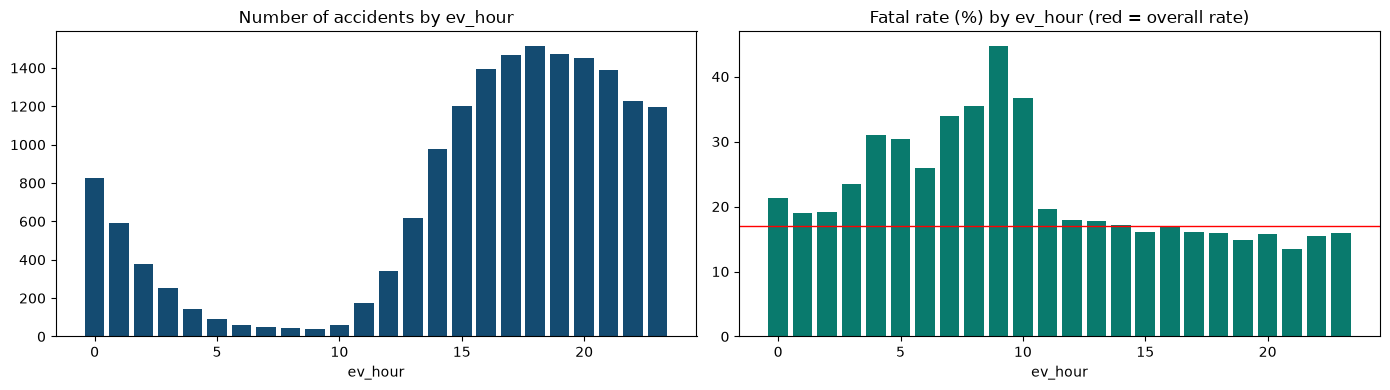

In [12]:
hour = learn["ev_hour"]

print("ev_hour missing:", hour.isnull().sum())
print()
print("Share of accidents with light_cond = DAYL, by hour:")
print((learn["light_cond"] == "DAYL").groupby(hour).mean().round(2).to_frame("DAYL share").T)
print()

hour_rate = learn.groupby("ev_hour")["fatal"].agg(["mean", "size"])
print("Fatal rate by light condition:")
print(learn.groupby("light_cond")["fatal"].agg(["mean", "size"]).round(3))
print()
print(pd.crosstab(learn["light_cond"].fillna("missing"),
                  pd.cut(hour, [-1, 5, 8, 11, 15, 18, 21, 23], labels=["0-5", "6-8", "9-11", "12-15", "16-18", "19-21", "22-23"])))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(hour_rate.index, hour_rate["size"], color="#144b71")
axes[0].set_title("Number of accidents by ev_hour")
axes[0].set_xlabel("ev_hour")
axes[1].bar(hour_rate.index, hour_rate["mean"] * 100, color="#097a6d")
axes[1].axhline(learn["fatal"].mean() * 100, color="red", linewidth=1)
axes[1].set_title("Fatal rate (%) by ev_hour (red = overall rate)")
axes[1].set_xlabel("ev_hour")
plt.tight_layout()
plt.show()

**What we see**

- The accidents are concentrated between 12h and 23h and also between 0h and 2h (with a minimum between 5h and 10h). For local time we would expect the opposite: a peak in the afternoon (12h to 18h) and a minimum during the night.
- The light condition does not match a local hour. The share of daylight is 91% to 99% from 12h to 22h, but it falls to 14% to 28% between 4h and 10h, and goes up again to 75% at 11h and 74% at 0h. In the cross table there are 1,216 accidents with daylight between 0h and 5h, which cannot be at local time.
- This looks like a Coordinated Universal Time (UTC) hour: the time zones of the USA are 5 to 8 hours behind UTC, which moves the afternoon peak to the evening (and to the first hours of the next day). So `ev_hour` is probably **not** the local hour as the dictionary says, which is one of the "instruments that lie" of the project. We cannot confirm it, since there is no time zone or state in the data.
- The fatal rate is high between 4h and 10h (from 26% to 45%) and between 13% and 18% in the afternoon and evening hours. This agrees with the light condition: night accidents are much more fatal (dark night 55.7%, night 29.6%) than daylight ones (15.5%).

<div style="background-color:#061b2e; padding:15px; border-radius:10px; color:#FFFFFF; margin-top:10px;">
  <b>DECISION FOR NB1</b>
</div>



- Do not treat `ev_hour` as a normal number. Test a circular transformation (sine and cosine of the hour) or groups of hours, and also test the combination with `light_cond` and `ev_month`, since the light condition is the real local information.
- Do not create features that assume a local hour (like "working hours" or "weekend night") from `ev_hour` without this check. We should mention this in the report.
- 19 missing values: a new category "missing" (if hours are put in groups) or the median hour, with an indicator.

<a id="sec-5-10"></a>
<div style="background-color:#e3f0f5; padding:20px; border-radius:10px; border-left:8px solid #097a6d; color:#097a6d;">
  <b>5.10. Summary of the Numerical Features</b>
</div>


| Feature | Problem found | Decision for NB1 |
|:---|:---|:---|
| `wx_temp`, `wx_dew_pt` | 0 as "not measured" (832 rows with both 0, 692 with dew point 0 and warm temperature), 31 temperatures above 130 °F, 268 dew points above temperature | Impossible values to missing, indicator, median of train; test temperature - dew point spread |
| `wx_temp_c` | Same as `wx_temp` converted | Drop |
| `altimeter` | 1,510 zeros, 54 without decimal point, 4 other impossible | Divide by 100 / missing, `no_weather` indicator |
| `eng_power` | Two units (HP and lbs), 171 zeros, 10.6% missing | Split in `hp` and `thrust_lbs` by `eng_type`, zeros to missing, log scale |
| `wind_dir_deg` | 4,387 zeros (3,543 with no wind speed), circular | Zeros with no speed to missing, sine/cosine or groups |
| `wind_vel_kts`, `gust_kts` | 21% missing, a gust of 1,077 kts, 24 gusts below the wind speed | Impossible to missing, `has_gust` from `gust_kts`; `gust_ind` not trusted |
| `vis_sm` | 2 impossible values (4,500 and 5,000), 445 above 10 | Impossible to missing, cap or indicator "above 10"; strong feature |
| `sky_ceil_ht` | 2 impossible heights, 114 inconsistencies with `sky_cond_ceil`, 0 means no ceiling | Impossible to missing, `has_ceiling`; strong feature |
| `apt_dist` | 52 values above 500 (probably feet), 77% zeros (real) | Divide by 5,280, `at_airport`, log or groups; strong feature |
| `apt_elev` | 34% missing (linked to `apt_dist` = 0), one 33,333 | 33,333 to missing, indicator; weak relation with the target |
| `acft_year` | 40% missing, 3 impossible years; "after the accident" by 1 to 2 years is normal | Aircraft age feature, indicator |
| `total_seats` | 37 zeros, 4 above 600; 50-600 are real airliners | Impossible to missing, log or groups |
| `num_eng` | 2 airplanes with 0 engines; 0 is real in gliders and balloons | Fix the 2, indicator for missing |
| `seat_vintage_ratio` | 45% missing, one infinite value, correlation of 0.95 with `total_seats` | Create after cleaning, keep as required, justify with these numbers |
| `pilot_age` | 12 impossible ages (0 to 7 and 115 to 214) | To missing, median, test groups |
| `ev_hour` | Looks like UTC, not local time | Circular transformation or groups, use `light_cond` as the local information |